# Synthetic weak-lensing walkthrough

This example runs the analysis sequence: galaxy images → shape measurements → stacked tangential shear → NFW halo-mass inference. It generates its own inputs. Basic NumPy and probability knowledge is sufficient.

The generated images are a deliberately simple demonstration, separate from the supplied simulation and realistic surveys: circular Gaussian galaxies, one halo, additive Gaussian pixel noise, and no intrinsic ellipticity, PSF, convergence or blending. The NFW shear is injected as the image shape parameter under the weak-shear approximation. Every source lies at a radial bin centre, so model evaluation and stacking use the same separation.

1. Generate and inspect the image catalogue.
2. Compare three shape estimators and their tangential profiles.
3. Infer mass jointly with source redshift, then fix the redshift.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from weak_lensing import analysis, plotting
from weak_lensing.demo import make_synthetic_catalogue

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
OUTPUT = ROOT / "outputs" / "synthetic"
OUTPUT.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180})

## Generate galaxy stamps

The catalogue contains 2,000 sources around a halo of mass $5\times10^{14}\,M_\odot/h$ at $z_h=0.3$, with source redshift $z_s=0.6$. Source angles and image noise are reproducible from seed 625. Positions are in arcseconds; image coordinates are in pixels.

Synthetic sources: 2,000
Injected mass: 5.000e+14 M_sun/h
Injected source redshift: 0.60


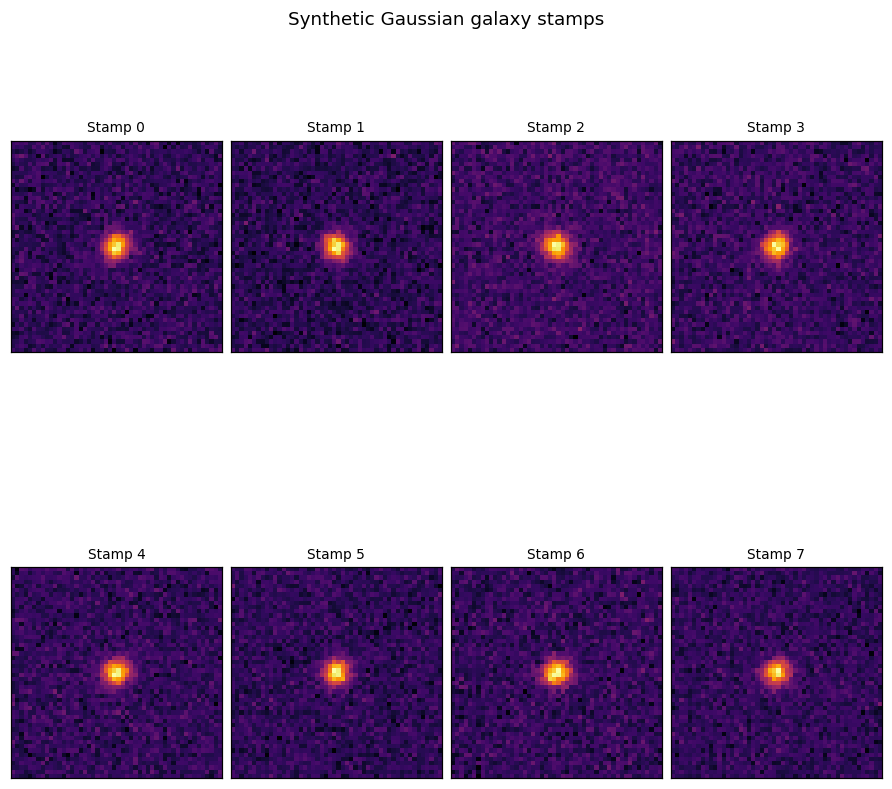

In [2]:
images, source_positions, halo_positions, truth = make_synthetic_catalogue()
print(f"Synthetic sources: {len(images):,}")
print(f"Injected mass: {truth['halo_mass_msun_over_h']:.3e} M_sun/h")
print(f"Injected source redshift: {truth['source_redshift']:.2f}")

fig, axes = plotting.galaxy_stamp_grid(images, n_stamps=8, n_cols=4)
fig.suptitle("Synthetic Gaussian galaxy stamps")
fig.savefig(OUTPUT / "synthetic_stamps.png", bbox_inches="tight")
plt.show()

## Measure shapes and stack the tangential signal

The three estimators are unweighted quadrupole moments, moments with a circular Gaussian weight of FWHM 4 pixels, and GalSim adaptive moments (HSM). The moment estimators use the definition $e_2=Q_{xy}/D$, where $D=Q_{xx}+Q_{yy}+2\sqrt{Q_{xx}Q_{yy}-Q_{xy}^2}$. Their second component therefore differs from the usual factor-of-two convention; HSM uses GalSim's `observed_shape.g1` and `g2`.

For each method, non-finite shapes are excluded from stacking. Errors are the standard error of halo–source pair measurements in each bin.

In [3]:
shapes = {
    "Unweighted": analysis.get_ellip_unweighted(images),
    "Weighted": analysis.get_ellip_weighted(images),
    "HSM": analysis.get_ellip_hsm(images),
}
profiles = {}
for name, components in shapes.items():
    radius, mean_shear, counts, sum_squared = analysis.get_tangential_shear_profile(
        components[:, 0], components[:, 1], source_positions, halo_positions
    )
    error = analysis.get_shear_uncertainties(mean_shear, sum_squared, counts)
    profiles[name] = (radius, mean_shear, error)
    failed = np.count_nonzero(~np.all(np.isfinite(components), axis=1))
    print(f"{name:10s}: {failed} failed measurements")

Unweighted: 1142 failed measurements
Weighted  : 0 failed measurements
HSM       : 0 failed measurements


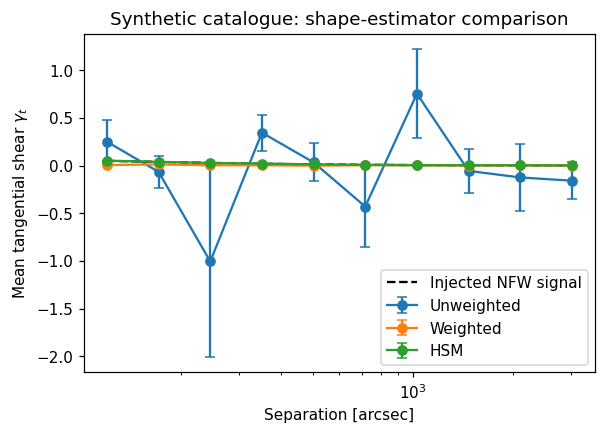

In [4]:
fig, ax = plotting.mean_shear_with_errorbars(
    [(*profile, name) for name, profile in profiles.items()]
)
radius, hsm_shear, hsm_error = profiles["HSM"]
injected_shear = analysis.get_nfw_tangential_shear(
    truth["halo_mass_msun_over_h"], truth["source_redshift"], radius
)
ax.plot(radius, injected_shear, color="black", linestyle="--", label="Injected NFW signal")
ax.set_title("Synthetic catalogue: shape-estimator comparison")
ax.legend()
fig.savefig(OUTPUT / "synthetic_shear.png", bbox_inches="tight")
plt.show()

The HSM profile is used for inference. Weighted moments suppress the outer image noise, but a fixed weight and the component convention affect the shear response. This comparison illustrates why a stable image measurement alone does not establish a calibrated shear estimator.

## Infer halo mass and source redshift

Use a 120 × 120 grid: linear mass from $3.0\times10^{14}$ to $14.8\times10^{14}\,M_\odot/h$ and source redshift from 0.31 to 0.8, with a uniform prior within these limits. The Gaussian likelihood treats radial-bin errors as independent. Joint posterior values sum to one over grid points.

In [5]:
halo_masses = np.linspace(3.0e14, 14.8e14, 120)
source_redshifts = np.linspace(0.31, 0.8, 120)
log_likelihood = analysis.get_joint_log_likelihood_grid(
    halo_masses, source_redshifts, radius, hsm_shear, hsm_error
)
posterior = analysis.get_normalised_posterior(log_likelihood)
best_mass, best_redshift = analysis.get_best_fit_from_posterior(
    halo_masses, source_redshifts, posterior
)
level_68, level_95 = analysis.get_credible_levels(posterior)
print(f"Joint grid maximum: M = {best_mass:.3e} M_sun/h, z_s = {best_redshift:.3f}")

Joint grid maximum: M = 4.388e+14 M_sun/h, z_s = 0.672


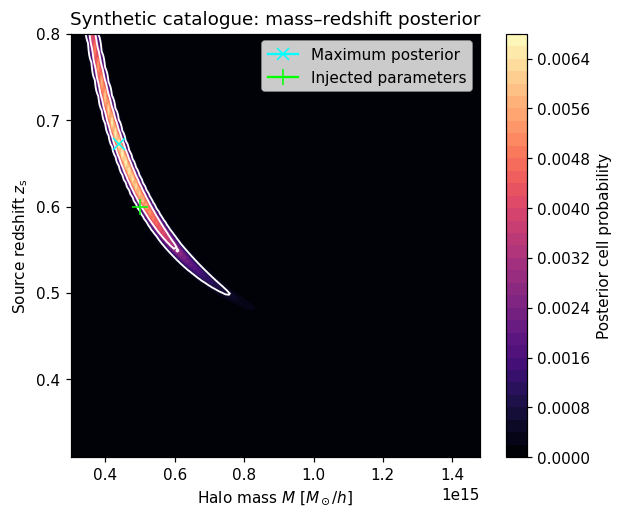

In [6]:
fig, ax = plotting.joint_posterior(
    halo_masses, source_redshifts, posterior, level_68, level_95,
    best_mass, best_redshift
)
ax.plot(truth["halo_mass_msun_over_h"], truth["source_redshift"],
        marker="+", color="lime", markersize=10, label="Injected parameters")
ax.set_xlabel(r"Halo mass $M$ [$M_\odot/h$]")
ax.set_title("Synthetic catalogue: mass–redshift posterior")
ax.legend()
fig.savefig(OUTPUT / "synthetic_joint_posterior.png", bbox_inches="tight")
plt.show()

A mass–redshift degeneracy is expected because both parameters change the shear amplitude. A grid maximum need not coincide exactly with the injection: the images contain noise and parameter values are sampled on a finite grid. Fixing the known source redshift isolates the mass constraint.

Fixed-redshift grid maximum: M = 5.182e+14 M_sun/h


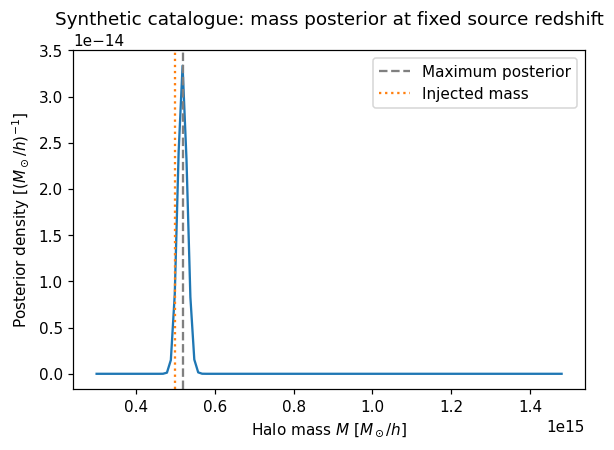

In [7]:
fixed_redshift = truth["source_redshift"]
log_likelihood_fixed = analysis.get_mass_log_likelihood(
    halo_masses, fixed_redshift, radius, hsm_shear, hsm_error
)
mass_posterior = analysis.get_normalised_1d_posterior(
    log_likelihood_fixed, halo_masses
)
best_mass_fixed = halo_masses[np.nanargmax(mass_posterior)]
print(f"Fixed-redshift grid maximum: M = {best_mass_fixed:.3e} M_sun/h")

fig, ax = plotting.mass_posterior(
    halo_masses, mass_posterior, best_mass_fixed, fixed_redshift
)
ax.axvline(truth["halo_mass_msun_over_h"], color="tab:orange",
           linestyle=":", label="Injected mass")
ax.set_xlabel(r"Halo mass $M$ [$M_\odot/h$]")
ax.set_title("Synthetic catalogue: mass posterior at fixed source redshift")
ax.legend()
fig.savefig(OUTPUT / "synthetic_mass_posterior.png", bbox_inches="tight")
plt.show()

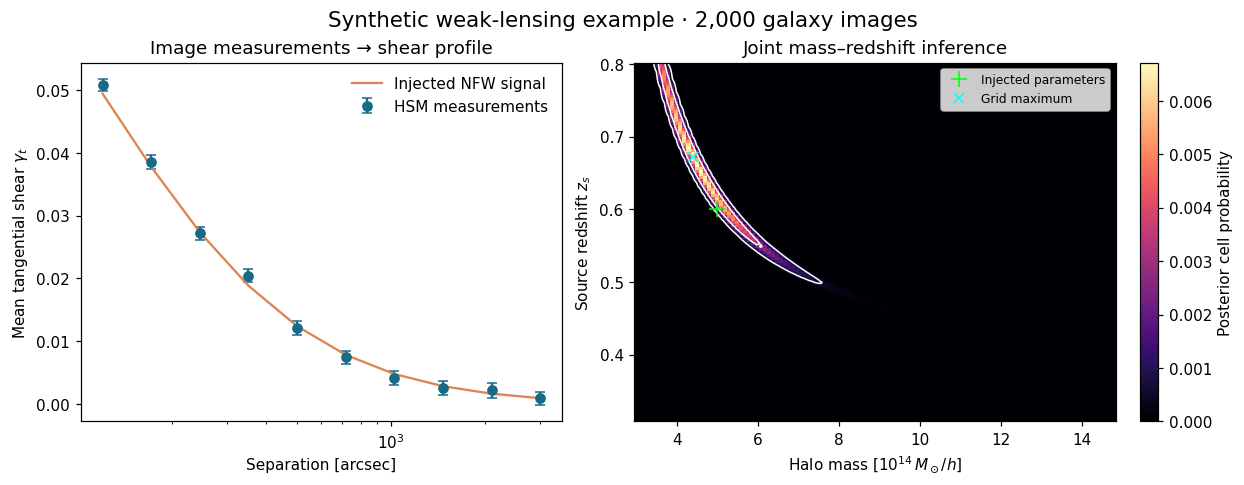

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.3), constrained_layout=True)
ax = axes[0]
ax.errorbar(radius, hsm_shear, yerr=hsm_error, fmt="o", capsize=3,
            color="#176b87", label="HSM measurements")
ax.plot(radius, injected_shear, color="#dd8452", label="Injected NFW signal")
ax.set(xscale="log", xlabel="Separation [arcsec]",
       ylabel=r"Mean tangential shear $\gamma_t$", title="Image measurements → shear profile")
ax.legend(frameon=False)

ax = axes[1]
mesh = ax.pcolormesh(halo_masses / 1e14, source_redshifts, posterior,
                     cmap="magma", shading="auto")
ax.contour(halo_masses / 1e14, source_redshifts, posterior,
           levels=[level_95, level_68], colors="white", linewidths=1)
ax.plot(truth["halo_mass_msun_over_h"] / 1e14, truth["source_redshift"],
        marker="+", color="lime", markersize=10, linestyle="none", label="Injected parameters")
ax.plot(best_mass / 1e14, best_redshift, marker="x", color="cyan",
        markersize=7, linestyle="none", label="Grid maximum")
ax.set(xlabel=r"Halo mass [$10^{14}\,M_\odot/h$]", ylabel=r"Source redshift $z_s$",
       title="Joint mass–redshift inference")
ax.legend(loc="upper right", fontsize=8)
fig.colorbar(mesh, ax=ax, label="Posterior cell probability")
fig.suptitle("Synthetic weak-lensing example · 2,000 galaxy images", fontsize=14)
for extension in ("png", "svg"):
    fig.savefig(OUTPUT / f"synthetic_overview.{extension}", bbox_inches="tight")
plt.show()

## Exercise: separate measurement noise from prior assumptions

Repeat the catalogue with `noise_sigma=40.0`, keeping the seed and all physical parameters fixed. Recompute shapes and profiles before inference. Compare HSM profile errors and the width of the fixed-redshift posterior; changing the noise does not change the prior range.

The error model assumes independent source–halo pairs. A survey analysis also needs shear calibration, PSF treatment and a covariance model that accounts for reused sources and correlated structure. See the method notes for these assumptions.

In [9]:
# Optional exercise: use this catalogue in the measurement cells above.
# noisier_images, noisier_positions, noisier_halos, noisier_truth = (
#     make_synthetic_catalogue(noise_sigma=40.0)
# )